In [1]:
import numpy as np
import fastplotlib as fpl
import matplotlib.pyplot as plt

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
Unable to find extension: VK_EXT_swapchain_colorspace
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 4.6 (Core Profile) Mesa 22.3.6


To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


In [2]:
import tifffile

In [3]:
movie = tifffile.imread("./dendrites_rect_filtered.tif")
movie.shape

(19999, 55, 53)

In [4]:
%matplotlib inline

In [5]:
Y = np.load("./Y.npy")

In [6]:
Y.shape

(2915, 10000)

In [7]:
Y

array([[0.00000e+00, 0.00000e+00, 9.00000e-01, ..., 5.60000e+00,
        2.80000e+01, 0.00000e+00],
       [0.00000e+00, 0.00000e+00, 0.00000e+00, ..., 2.46600e+02,
        2.36950e+02, 0.00000e+00],
       [4.95000e+00, 4.95000e+00, 4.95000e+00, ..., 1.66400e+02,
        1.43700e+02, 0.00000e+00],
       ...,
       [2.42315e+03, 2.42315e+03, 2.42315e+03, ..., 2.07930e+03,
        3.17930e+03, 0.00000e+00],
       [1.87645e+03, 2.05190e+03, 2.10095e+03, ..., 2.58230e+03,
        2.50565e+03, 0.00000e+00],
       [1.33820e+03, 1.33820e+03, 1.28915e+03, ..., 1.37780e+03,
        1.33485e+03, 0.00000e+00]], dtype=float32)

In [8]:
Y.shape
Y = Y[:, :-1]

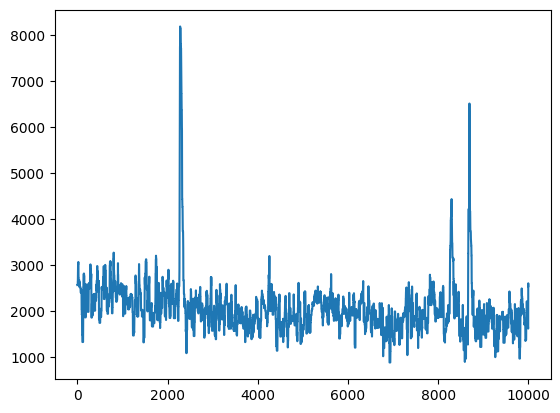

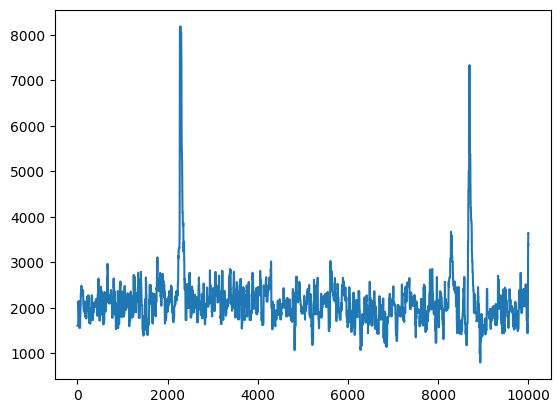

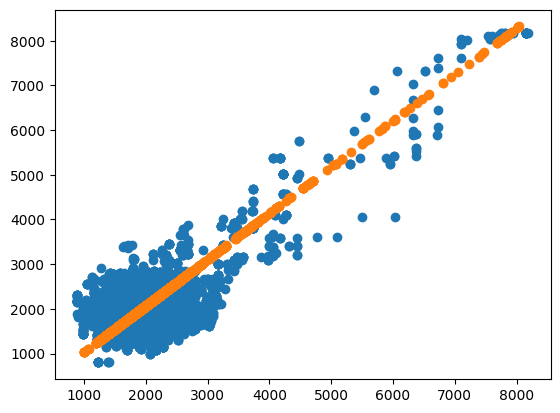

In [39]:
i1 = 1202
i2 = 1203

plt.plot(Y[i1, :])
plt.show()
plt.plot(Y[i2, :])
plt.show()

plt.scatter(Y[i1, :], Y[i2, :])
plt.scatter(projections[:, 0], projections[:, 1])

In [93]:
Y = Y.astype(np.float64)
n = Y.shape[1]
i = i1
j = i2
yyt = Y @ Y.T
ysum = np.sum(Y, axis=1)
(yyt[i, j] - 1 / n * ysum[i] * ysum[j]) / (yyt[i, i] - 1 / n * ysum[i]**2)

np.float64(0.6813455892406317)

In [132]:
from numba import guvectorize, float64, int64, float32
from itertools import product

In [195]:
@guvectorize([(float64[:, :], float64[:], float64[:, :])], "(n, n),(n)->(n, n)")
def corr_vec(yyt: np.ndarray, ysum: np.ndarray, matrix: np.ndarray):
    for i in range(yyt.shape[0]):
        for j in range(yyt.shape[0]):
            matrix[i, j] = (yyt[i, j] - 1 / n * ysum[i] * ysum[j]) / (yyt[i, i] - 1 / n * ysum[i]**2)

In [196]:
Y = Y.astype(np.float64)
n = Y.shape[1]
i = i1
j = i2
yyt = Y @ Y.T
ysum = np.sum(Y, axis=1)

In [199]:
ms = np.zeros((Y.shape[0], Y.shape[0]), dtype=np.float64)
corr_vec(yyt, ysum, ms)

array([[ 1.00000000e+00,  1.35527948e-02,  1.80612519e-01, ...,
         3.88027593e+00,  1.00591787e+00, -4.63753654e-01],
       [ 2.08789514e-03,  1.00000000e+00, -1.60653735e-01, ...,
        -2.91027727e+00, -2.45409604e+00, -2.96967944e-01],
       [ 1.06351286e-02, -6.14053067e-02,  1.00000000e+00, ...,
         2.29253733e+00,  1.56976882e+00,  3.88769243e-01],
       ...,
       [ 3.61818008e-04, -1.76149784e-03,  3.63035493e-03, ...,
         1.00000000e+00,  6.30442346e-01,  1.41204471e-01],
       [ 1.64072774e-04, -2.59827869e-03,  4.34825293e-03, ...,
         1.10278743e+00,  1.00000000e+00,  2.52767720e-01],
       [-2.75078551e-04, -1.14340250e-03,  3.91621374e-03, ...,
         8.98235600e-01,  9.19214778e-01,  1.00000000e+00]])

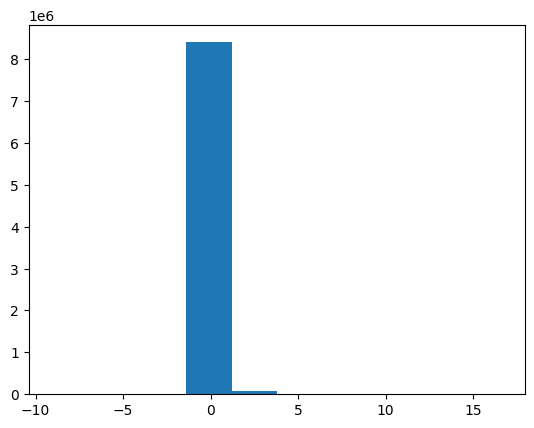

In [ ]:
vs = 

In [190]:
x = Y[i1, :]
y = Y[i2, :]

# Step 1: Calculate means of x and y
x_mean = np.mean(x)
y_mean = np.mean(y)

# Step 2: Calculate slope (m) using inner products
m = (np.dot(x, y) - n * x_mean * y_mean) / (np.dot(x, x) - n * x_mean**2)

v1 = np.array([m, 1])
v1[0] += x_mean
v1[1] += y_mean

v1 = v1 / np.sqrt(np.sum(v1**2))

X = np.column_stack([x, y])
projections = (X @ v1)[:, None] * v1  # n x 2 matrix of projected points on v1
orthogonal_distances = np.linalg.norm(X - projections, axis=1)  # Euclidean distances
orthogonal_distances = orthogonal_distances**2

# Sum of orthogonal distances
sum_of_distances = np.sum(orthogonal_distances) / X.shape[0] / 1000
# print("Sum of orthogonal distances:", sum_of_distances)

In [183]:
from tqdm import tqdm

In [194]:
corr_matrix = np.zeros(ms.shape, dtype=np.float64)

for i in tqdm(range(yyt.shape[0])):
    for j in range(yyt.shape[0]):
        v1 = np.array([ms[i, j], 1])
        v1[0] += x_mean
        v1[1] += y_mean
        
        v1 = v1 / np.sqrt(np.sum(v1**2))
        
        X = np.column_stack([x, y])
        projections = (X @ v1)[:, None] * v1  # n x 2 matrix of projected points on v1
        orthogonal_distances = np.linalg.norm(X - projections, axis=1)  # Euclidean distances
        orthogonal_distances = orthogonal_distances**2
        
        # Sum of orthogonal distances
        sum_of_distances = np.sum(orthogonal_distances) / X.shape[0] / 1000
        corr_matrix[i, j] = sum_of_distances

  5%|███████▏                                                                                                                             | 157/2915 [02:06<36:59,  1.24it/s]


KeyboardInterrupt: 

In [95]:
v1

array([0.69477636, 0.71922585])

In [96]:
v1[1] / v1[0]

np.float64(1.0351904465071218)

In [10]:
from sklearn.metrics import pairwise_distances

In [11]:
# Step i: Create the matrix and compute SVD
X = np.column_stack((Y[i1, :], Y[i2, :]))  # n x 2 matrix with x1 and x2 as columns
u, s, vt = np.linalg.svd(X, full_matrices=False)

# The biggest singular vector is the first column of Vt (since SVD returns sorted singular values)
v1 = vt[0, :]  # v1 is the largest singular vector, represented as a 2-element vector

projections = (X @ v1)[:, None] * v1  # n x 2 matrix of projected points on v1
orthogonal_distances = np.linalg.norm(X - projections, axis=1)  # Euclidean distances
orthogonal_distances = orthogonal_distances**2

# Sum of orthogonal distances
sum_of_distances = np.sum(orthogonal_distances) / X.shape[0] / 1000
print("Sum of orthogonal distances:", sum_of_distances)

Sum of orthogonal distances: 110.84054


In [20]:
m / 1

np.float32(0.34344047)

In [12]:
def corr0(u, v):
    # Step i: Create the matrix and compute SVD
    X = np.column_stack((u, v))  # n x 2 matrix with x1 and x2 as columns
    u, s, vt = np.linalg.svd(X, full_matrices=False)
    
    # The biggest singular vector is the first column of Vt (since SVD returns sorted singular values)
    v1 = vt[0, :]  # v1 is the largest singular vector, represented as a 2-element vector
    
    projections = (X @ v1)[:, None] * v1  # n x 2 matrix of projected points on v1
    orthogonal_distances = np.linalg.norm(X - projections, axis=1)  # Euclidean distances
    orthogonal_distances = orthogonal_distances**2
    
    # Sum of orthogonal distances
    sum_of_distances = np.sum(orthogonal_distances) / X.shape[0] / 1000
    return sum_of_distances

def corr(u, v):
    n = u.size

    x = u
    y = v
    
    # Step 1: Calculate means of x and y
    x_mean = np.mean(x)
    y_mean = np.mean(y)
    
    # Step 2: Calculate slope (m) using inner products
    m = (np.dot(x, y) - n * x_mean * y_mean) / (np.dot(x, x) - n * x_mean**2)
    
    projections = (X @ v1)[:, None] * v1  # n x 2 matrix of projected points on v1
    orthogonal_distances = np.linalg.norm(X - projections, axis=1)  # Euclidean distances
    orthogonal_distances = orthogonal_distances**2
    
    # Sum of orthogonal distances
    sum_of_distances = np.sum(orthogonal_distances) / X.shape[0] / 1000
    return sum_of_distances

In [16]:
u = Y[i1, :50]
v = Y[i2, :50]

In [17]:
%%timeit
corr(u, v)

26.5 μs ± 104 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [30]:
np.unravel_index(1202, shape=(55, 53))

(np.int64(22), np.int64(36))

In [163]:
B = np.load("./B.npy")

In [164]:
d = 1.0 / np.sum(B.astype(np.float64), axis=1)
A = np.diag(d) @ B

In [204]:
B = ms

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting int64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas(css_height='400px', css_width='700px')
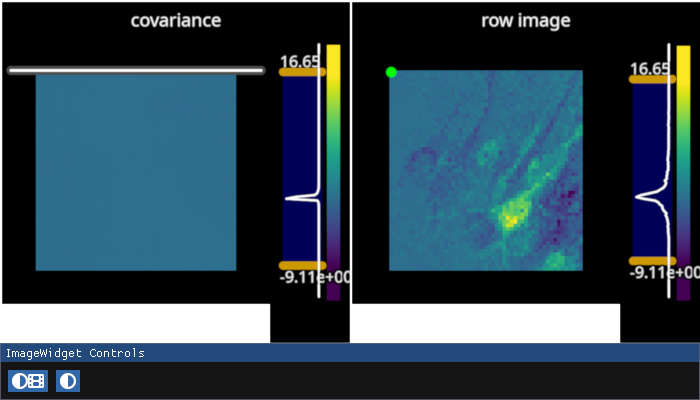

In [205]:
img = B[0].reshape(55, 53)

iw = fpl.ImageWidget(
    data=[B, img],
    cmap="viridis",
    names=["covariance", "row image"],
    figure_kwargs={"size": (700, 400), "controller_ids": [[0, 1]]}
)

scatter_point = iw.figure[0, 1].add_scatter(np.array([[0, 0, 0]]), colors=(0., 1., 0., 0.3), sizes=10)

selector_cov = iw.managed_graphics[0].add_linear_selector(axis="y")

for g in iw.managed_graphics:
    g.vmin, g.vmax = B.min(), B.max()

@selector_cov.add_event_handler("selection")
def update_img(ev):
    ix = ev.get_selected_index()
    iw.managed_graphics[1].data = B[ix].reshape(55, 53)

    row, col = np.unravel_index(ix, (55, 53))

    scatter_point.data[:, 0] = col
    scatter_point.data[:, 1] = row


iw.show()

In [206]:
iw.cmap = "seismic"

In [47]:
selector_cov.selection = i1

In [46]:
selector_cov.selection = i2

In [162]:
for g in iw.managed_graphics:
    g.vmin, g.vmax = -10, 10

In [10]:
B.min(), B.max()

(np.float32(0.0), np.float32(1.3595536))

In [ ]:
img = B[0].reshape(55, 53)

iw = fpl.ImageWidget(
    data=[B, img],
    cmap="viridis",
    names=["covariance", "row image"],
    figure_kwargs={"size": (700, 400), "controller_ids": [[0, 1]]}
)

selector_cov = iw.managed_graphics[0].add_linear_selector(axis="y")

for g in iw.managed_graphics:
    g.vmin, g.vmax = B.min(), B.max()

@selector_cov.add_event_handler("selection")
def update_img(ev):
    ix = ev.get_selected_index()
    iw.managed_graphics[1].data = B[ix].reshape(55, 53)


iw.show()